In [2]:
#
#
#
import arslabrobotics as ar
import numpy as np
import scipy

data = np.loadtxt("motor_data_filtered.txt")
(rows, _) = data.shape

arx = ar.identification.ARXSolver(data, 7, 0)
(a, b) = arx.solve()

print(a,b)

# Discrete system mnodel
system = ar.identification.ARXModel(a, b)
(A, B, C) = system.state_space()

delta_t = 0.001

print("State Matrix:\n", A)
print("Input Matrix:\n", B)


[-0.34092814606979704, -0.3656052954402311, -0.10361024135742392, -0.06974646500168762, -0.03766195560084602, 0.0004809201455943102, -0.03809650359398147] [3.8333730398180483]
State Matrix:
 [[ 3.40928146e-01  3.65605295e-01  1.03610241e-01  6.97464650e-02
   3.76619556e-02 -4.80920146e-04  3.80965036e-02]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   1.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  1.00000000e+00  0.0000

In [19]:

Q = np.eye( 7, dtype=np.float32) * 0.1
R = np.eye( 1, dtype=np.float32) * 100

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[0.02773902 0.02081811 0.00751521 0.004536   0.002467   0.00086333
  0.00162602]]


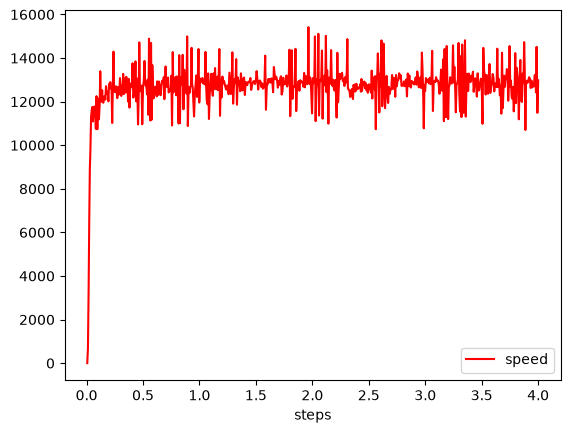

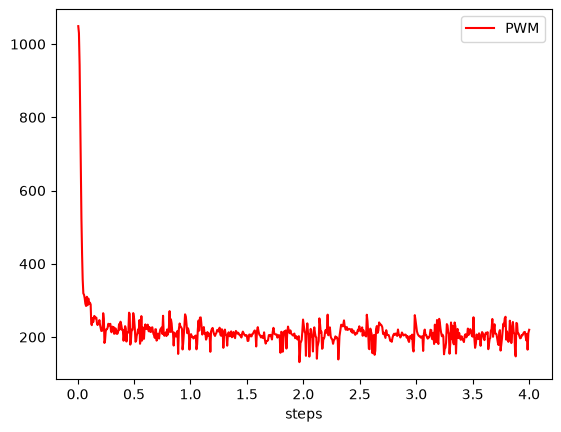

In [20]:
motor = ar.system.MotorDriver()
motor.open()
motor.reset()

x = np.array([ 0., 0., 0., 0., 0., 0. , 0.])

target = 16000.0
set_point = np.array([target] * 7)

#x = np.array([-15000] * 7)

dps = ar.data.DataPlotter()
dps.set_x("steps")
dps.add_y("speed", "speed")

dpf = ar.data.DataPlotter()
dpf.set_x("steps")
dpf.add_y("PWM", "PWM")

t = ar.utils.Time()

t.start()
prev_enc = 0
motor.pwm(0)

while t.get() < 4:

    t.sleep(0.001)
    enc = motor.encoder()
    delta_t = t.elapsed()
    speed = (enc - prev_enc) / delta_t
    prev_enc = enc

    # shift data
    x[1:7] = x[0:6]
    x[0] = speed
    
    u = - K @ (x - set_point)
    motor.pwm(u[0])
    
    dps.append_x(t.get())
    dps.append_y("speed", x[0])
    dpf.append_x(t.get())
    dpf.append_y("PWM", u[0])

dps.plot()
dpf.plot()
motor.pwm(0)
